# Magnetic Steering of SPION Suspensions at a Bifurcation — Data Analysis

This notebook examines simultaneous optical recordings upstream of the bifurcation and in branches A and B during E02. This first stage imports the measurements, establishes a shared time axis, and displays the raw signals and event markers.

Injection-rate units and the concentrations of the test and reference suspensions require confirmation before quantitative analysis.

## Setup

`project_dir` locates the repository; `data_dir` contains the original measurements. The selected wavelength is $\lambda = 640\,\mathrm{nm}$. Imports and analysis parameters are defined here.

In [34]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

project_dir = Path("/Users/lukaskroll/Documents/10_Projekte/dynano/sensor_modell")
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.spectral_sensor.io import read_sensor_csv, read_marker_rows, read_protocol
from src.spectral_sensor.preprocessing import synchronize_time, marker_time, select_time_window
from src.spectral_sensor.plotting import plot_measurements, save_plot
from src.spectral_sensor.analysis import get_min

experiment_dir = project_dir / "experiments/E02_20x15_mag_steering"
data_dir = experiment_dir / "data"
results_dir = experiment_dir / "results"
wavelength_nm = 640

sensor_styles = {
    "sensor_0": {"color": "#004488"},
    "sensor_1": {"color": "#DDAA33"},
    "sensor_2": {"color": "#BB5566"},
}

## Measurement metadata

- Experiment: E02; batch: XL004.
- Operator: Lukas Kroll; location: Laboratory A701, FH Dortmund.
- Protocol start: 2026-07-08T13:01:43.977864; filename timestamp: 20260708_113243. These source timestamps are retained separately. The May date in the earlier report is inconsistent with these files.
- Sensor settings in `Protocol.md`: ATIME 0, ASTEP 8993, GAIN 1, IRMAIN 25, IROPP 25, VISM 255, VISLR 255.
- Physical sensor IDs and system roles below follow `E02_Evaluation.md`; software IDs are checked against the measurement files.

`read_protocol` extracts the supported protocol fields. `sensor_metadata` preserves the distinction between physical identity, recorded software ID, and system role.

In [35]:
sensor_metadata = pd.DataFrame([
    {"sensor": "sensor_0", "software_id": 1002, "role": "Upstream reference", "file": "SpectralSensor 3_20260708_113243.csv"},
    {"sensor": "sensor_1", "software_id": 1001, "role": "Branch A", "file": "SpectralSensor 2_20260708_113243.csv"},
    {"sensor": "sensor_2", "software_id": 1000, "role": "Branch B", "file": "SpectralSensor 1_20260708_113243.csv"},
]).set_index("sensor")

protocol_metadata = read_protocol(data_dir / "Protocol.md")
display(pd.DataFrame.from_dict(protocol_metadata, orient="index", columns=["value"]))
display(sensor_metadata)

,value
protocol_file,Protocol.md
experiment_name,E02_C20x15_50%_static_test
batch_number,XL004
start_time,2026-07-08T13:01:43.977864
timeline_band_nm,640
timeline_bands_nm,[640]


,software_id,role,file
sensor,,,
sensor_0,1002,Upstream reference,SpectralSensor 3_20260708_113243.csv
sensor_1,1001,Branch A,SpectralSensor 2_20260708_113243.csv
sensor_2,1000,Branch B,SpectralSensor 1_20260708_113243.csv


## Data import and synchronization

`read_sensor_csv` and `read_marker_rows` load the original tables. `synchronize_time` uses one shared origin $t_0$ for all recordings, with $t = (t_{\mathrm{raw}} - t_0)/1000$ in seconds. It does not correct independent clock offsets. The original timestamps remain available.

In [36]:
sensor_data = {
    sensor: read_sensor_csv(data_dir / row["file"])
    for sensor, row in sensor_metadata.iterrows()
}
markers = read_marker_rows(data_dir / "Markers_20260708_113243.csv")

for sensor, row in sensor_metadata.iterrows():
    assert sensor_data[sensor]["sensor"].eq(row["software_id"]).all(), sensor

synced_sensors, synced_markers, start_ms = synchronize_time(sensor_data, markers)
display(synced_markers)

,line_number,marker_id,timestamp_raw_ms,label,parse_error,time_s
0,1,99,11406248,"STEP_1: Start sensor (upstream, downstream, re...",,0.000
1,2,99,11406537,STEP_2: Move robot to C20_full_off @ 1.0,,0.289
2,3,99,11409855,STEP_3: Start peristaltic (10.0 ml/min),,3.607
3,4,99,11412204,STEP_4: Wait (20 min Sensor warm up),,5.956
4,5,99,12652479,STEP_5: Warte auf Continue (prepare 100% ref s...,,1246.231
5,6,99,12671755,STEP_6: Inject syringe 200.0 ul @ 10.0 ul/min,,1265.507
6,7,99,12672750,STEP_7: Warte auf Continue (Reference no Magnet),,1266.502
7,8,99,12862433,STEP_8: Inject syringe 50.0 ul @ 10.0 ul/min,,1456.185
8,9,99,12956988,STEP_9: Inject syringe 50.0 ul @ 10.0 ul/min,,1550.740
9,10,99,13052072,STEP_10: Inject syringe 50.0 ul @ 10.0 ul/min,,1645.824


## Raw signals

`plot_measurements` displays the ADC signal $I(t)$ and recorded event times. Sensor colors retain the physical identities used in E01. These plots provide the initial check of timing, signal range, and injection responses.

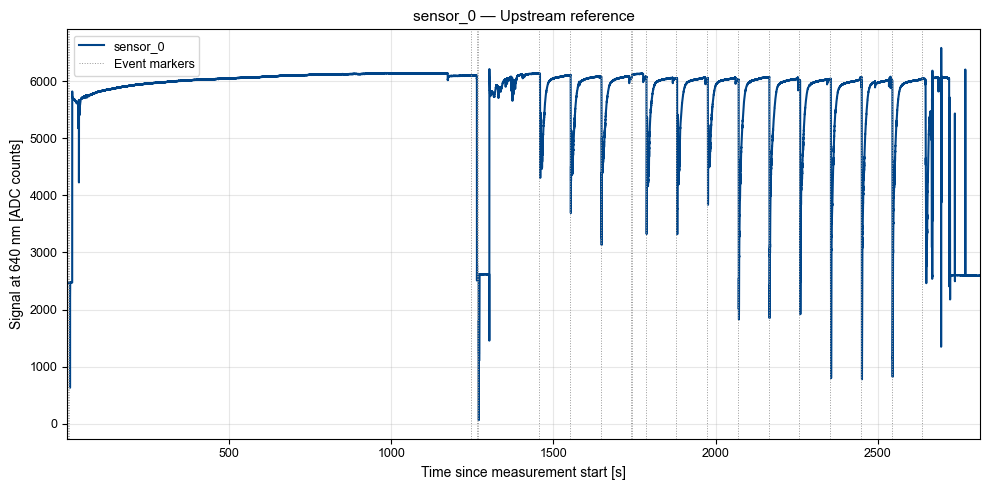

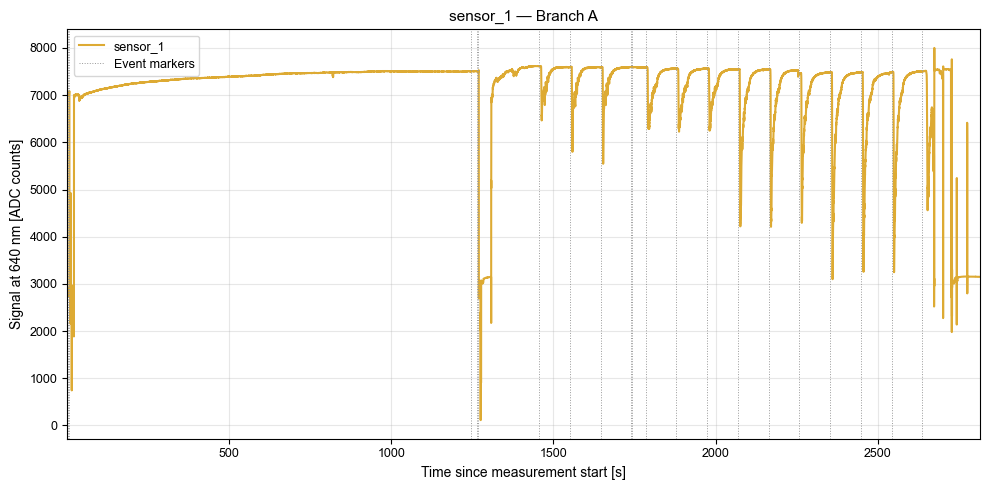

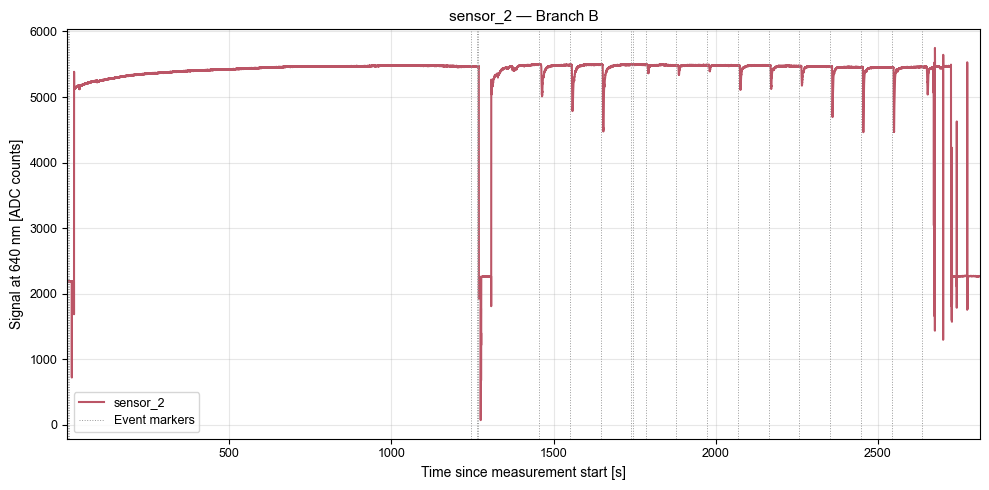

In [37]:
for sensor, row in sensor_metadata.iterrows():
    fig, ax = plot_measurements(
        {sensor: synced_sensors[sensor]},
        synced_markers,
        time_column="time_s",
        signal_column=str(wavelength_nm),
        xlabel="Time since measurement start [s]",
        ylabel=f"Signal at {wavelength_nm} nm [ADC counts]",
        title=f"{sensor} — {row["role"]}",
        sensor_styles=sensor_styles,
    )
    plt.show()

## Analysis

The recorded sequence contains one reference injection at STEP 6 and twelve test injections: STEP 8–10 (50 µL, magnet off), STEP 13–15 (50 µL, magnet on), STEP 16–18 (100 µL, magnet on), and STEP 19–21 (150 µL, magnet on). STEP identifiers differ from the DataFrame row index.

After confirming the injection rate and suspension concentrations, define the baseline and integration windows explicitly. The existing concentration curves and AES comparison are prior results; they are not reproduced by this initial notebook.

In [38]:
from src.spectral_sensor.preprocessing import marker_time, select_time_window
from src.spectral_sensor.analysis import get_min

reference_start_s = marker_time(synced_markers, 5)
reference_end_s = marker_time(synced_markers, 7)

reference_window = select_time_window(
    synced_sensors,
    start_s=reference_start_s,
    window_s=reference_end_s - reference_start_s,
)

reference_values = get_min(
    reference_window,
    wavelength_nm=wavelength_nm,
)

reference_values

{'sensor_0': np.int64(63), 'sensor_1': np.int64(114), 'sensor_2': np.int64(69)}

In [39]:
# Cut Steps

start_s = marker_time(synced_markers, 7)
window_s = 60.0

injection_window = select_time_window(
    synced_sensors,
    start_s=start_s,
    window_s=window_s,
)

injection_window["sensor_1"][
    ["time_from_start_s", str(wavelength_nm)]
].head()

,time_from_start_s,640
19233,0.000,7614
19234,0.075,7615
19235,0.151,7615
19236,0.227,7615
19237,0.302,7613


### Calculate Baseline

In [40]:
from src.spectral_sensor.normalization import baseline_correction

baseline_window_s = 10.0

corrected_window = baseline_correction(
    synced_sensors,
    injection_window,
    wavelength_nm=wavelength_nm,
    start_s=start_s,
    baseline_window_s=baseline_window_s,
)

baseline_values = pd.Series({
    sensor: table["baseline_adc"].iloc[0]
    for sensor, table in corrected_window.items()
}, name="baseline_adc")

baseline_values

sensor_0    6129.0
sensor_1    7616.0
sensor_2    5492.0
Name: baseline_adc, dtype: float64

### Normalize Signal

$$a(t)=\frac{I_\mathrm{baseline}-I(t)}
{I_\mathrm{baseline}-I_\mathrm{reference}}$$


In [41]:
from src.spectral_sensor.normalization import normalize_signal

normalized_window = normalize_signal(
    corrected_window,
    reference_values,
)

normalized_window["sensor_1"][
    ["time_from_start_s", "640", "baseline_adc",
     "reference_adc_100pct", "normalized_0_1"]
].head()

,time_from_start_s,640,baseline_adc,reference_adc_100pct,normalized_0_1
19233,0.000,7614,7616.0,114,0.000267
19234,0.075,7615,7616.0,114,0.000133
19235,0.151,7615,7616.0,114,0.000133
19236,0.227,7615,7616.0,114,0.000133
19237,0.302,7613,7616.0,114,0.000400


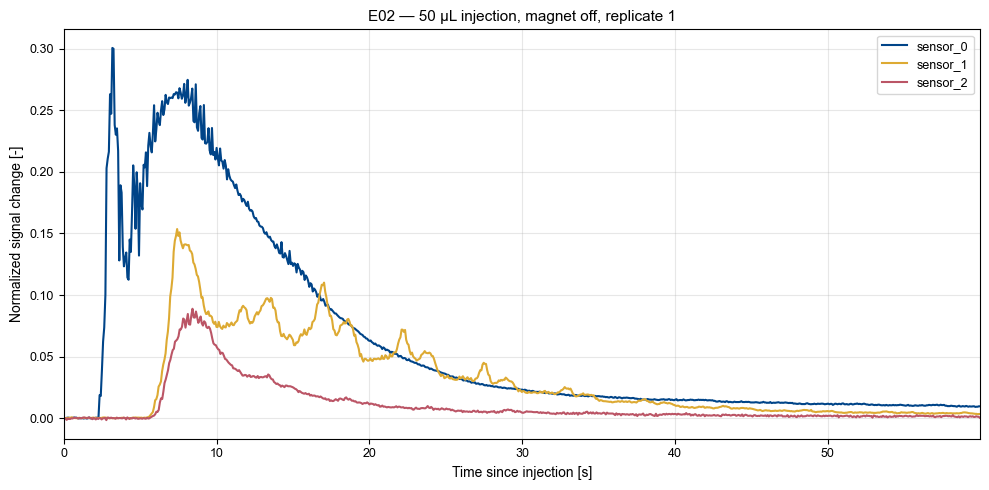

In [42]:
from src.spectral_sensor.plotting import plot_timeseries

fig, ax = plot_timeseries(
    normalized_window,
    time_column="time_from_start_s",
    signal_column="normalized_0_1",
    xlabel="Time since injection [s]",
    ylabel="Normalized signal change [-]",
    title="E02 — 50 µL injection, magnet off, replicate 1",
    sensor_styles=sensor_styles,
)

## Injection Assignment

`injections` assigns each injection marker to its volume, magnet condition, and replicate; `marker_index` refers to the row index in `synced_markers`.

In [43]:
injections = pd.DataFrame({
    "marker_index": [7, 8, 9, 12, 13, 14, 15, 16, 17, 18, 19, 20],
    "volume_ul": [50, 50, 50, 50, 50, 50, 100, 100, 100, 150, 150, 150],
    "magnet": ["off"] * 3 + ["on"] * 9,
    "replicate": [1, 2, 3] * 4,
})

injections["label"] = injections["marker_index"].map(
    synced_markers["label"]
)

injections

,marker_index,volume_ul,magnet,replicate,label
0,7,50,off,1,STEP_8: Inject syringe 50.0 ul @ 10.0 ul/min
1,8,50,off,2,STEP_9: Inject syringe 50.0 ul @ 10.0 ul/min
2,9,50,off,3,STEP_10: Inject syringe 50.0 ul @ 10.0 ul/min
3,12,50,on,1,STEP_13: Inject syringe 50.0 ul @ 10.0 ul/min
4,13,50,on,2,STEP_14: Inject syringe 50.0 ul @ 10.0 ul/min
5,14,50,on,3,STEP_15: Inject syringe 50.0 ul @ 10.0 ul/min
6,15,100,on,1,STEP_16: Inject syringe 100.0 ul @ 10.0 ul/min
7,16,100,on,2,STEP_17: Inject syringe 100.0 ul @ 10.0 ul/min
8,17,100,on,3,STEP_18: Inject syringe 100.0 ul @ 10.0 ul/min
9,18,150,on,1,STEP_19: Inject syringe 150.0 ul @ 10.0 ul/min


## Injection Processing

`prepare_injections` extracts each injection window, subtracts the local pre-injection baseline, and normalizes the response using the sensor-specific reference intensity.

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Injection 7 — STEP_21: Inject syringe 150.0 ul @ 10.0 ul/min'}, xlabel='Time since injection [s]', ylabel='Normalized signal change [-]'>)

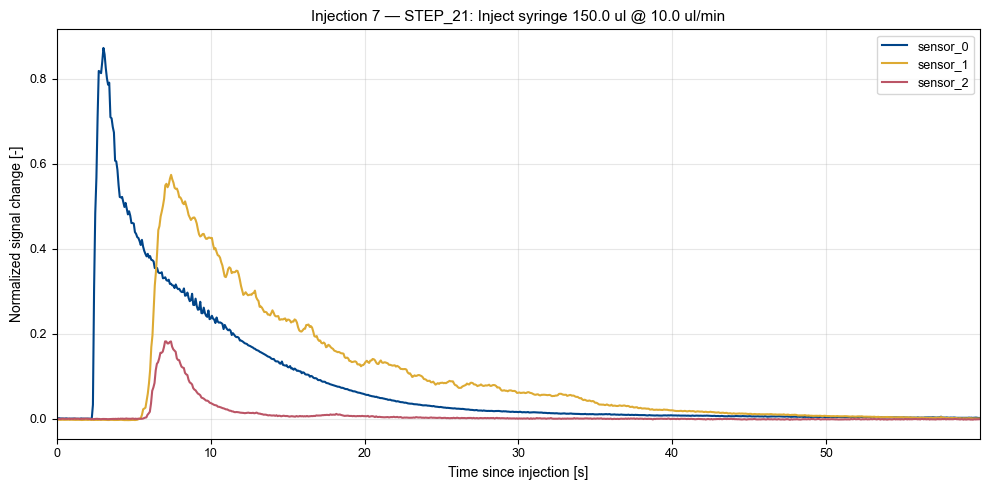

In [44]:
from src.spectral_sensor.normalization import prepare_injections

window_s = 60.0
baseline_window_s = 10.0

normalized_injections = prepare_injections(
    synced_sensors,
    synced_markers,
    injections,
    reference_values,
    wavelength_nm=wavelength_nm,
    window_s=window_s,
    baseline_window_s=baseline_window_s,
)

len(normalized_injections)
inj_12 = normalized_injections[20]
plot_timeseries(
    inj_12,
    time_column="time_from_start_s",
    signal_column="normalized_0_1",
    xlabel="Time since injection [s]",
    ylabel="Normalized signal change [-]",
    title=f"Injection 7 — {injections.loc[11, 'label']}",
    sensor_styles=sensor_styles,
)

## Injection Data Export

`export_injection` saves raw, baseline-corrected, and normalized signals for branches A and B and the reference sensor, retaining their individual time vectors.

In [45]:
from src.spectral_sensor.io import export_injection, export_injection_info

sensor_roles = {
    "sensor_1": "A",
    "sensor_2": "B",
    "sensor_0": "Ref",
}

output_dir = results_dir / "sample_csv"

for injection in injections.itertuples(index=False):
    condition = (
        f"{injection.volume_ul}R"
        if injection.magnet == "off"
        else str(injection.volume_ul)
    )
    filename = f"E02_{condition}_AB_{injection.replicate}.csv"

    export_injection(
        normalized_injections[injection.marker_index],
        sensor_roles,
        wavelength_nm,
        output_dir / filename,
    )

export_injection_info(
    normalized_injections=normalized_injections,
    injections=injections,
    sensor_roles=sensor_roles,
    protocol_metadata=protocol_metadata,
    reference_window=reference_window,
    data_dir=data_dir,
    wavelength_nm=wavelength_nm,
    window_s=window_s,
    baseline_window_s=baseline_window_s,
    path=output_dir / "info.txt",
)

print(f"Exported {len(injections)} injection files.")

Exported 12 injection files.


## Injection Response Plots

Raw and normalized sensor responses are plotted against time since injection and exported as PDF and PNG files.

In [46]:
plot_settings = [
    (
        str(wavelength_nm),
        f"Signal intensity at {wavelength_nm} nm (ADC counts)",
        "raw",
    ),
    (
        "normalized_0_1",
        "Normalized signal change (dimensionless)",
        "normalized",
    ),
]

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "mathtext.fontset": "dejavusans",
})

sensor_styles["sensor_1"].update(label="Branch A (1001)")
sensor_styles["sensor_2"].update(label="Branch B (1000)")
sensor_styles["sensor_0"].update(label="Reference (1002)")

for injection in injections.itertuples(index=False):
    sensors = normalized_injections[injection.marker_index]

    # Retain the recorded STEP and injection-rate text in filenames.
    step, description = injection.label.split(":", 1)
    volume, rate = description.split("Inject syringe", 1)[1].split("@")

    volume_tag = f"{float(volume.split()[0]):g}uL"
    rate_tag = (
        f"{float(rate.split()[0]):g}"
        f"{rate.split()[1].replace('ul', 'uL').replace('/', '-')}"
    )
    filename = (
        f"{step.strip().replace('STEP_', 'STEP_')}_"
        f"{volume_tag}_{rate_tag}_rep{injection.replicate}_"
        f"{wavelength_nm}nm"
    )

    condition = (
        f"{injection.volume_ul}R"
        if injection.magnet == "off"
        else str(injection.volume_ul)
    )
    sample_name = f"E02_{condition}_AB_{injection.replicate}"

    title = (
        rf"$V_\mathrm{{inj}} = {injection.volume_ul}\,\mu\mathrm{{L}}$"
        f", replicate {injection.replicate}\n"
        f"Sample pair: {sample_name} | "
        f"magnet {injection.magnet} | {step.strip()}"
    )
    

    for signal_column, ylabel, signal_type in plot_settings:
        fig, ax = plot_timeseries(
            sensors,
            time_column="time_from_start_s",
            signal_column=signal_column,
            xlabel="Time after injection (s)",
            ylabel=ylabel,
            title=title,
            sensor_styles=sensor_styles,
        )

        ax.set_xlim(0, window_s)

        if signal_type == "normalized":
            ax.set_ylim(0, 1)

        fig.tight_layout()

        save_plot(
            fig,
            results_dir / f"injection_plots_{signal_type}",
            f"{filename}_{signal_type}",
        )
        plt.close(fig)

## Injection Statistics

`injection_metrics` calculates peaks, integrals, and within-window signal statistics for each sensor; experimental metadata identify the corresponding injection and replicate.

In [47]:
from src.spectral_sensor.analysis import injection_metrics

roles = {
    "sensor_1": ("Branch A", "A"),
    "sensor_2": ("Branch B", "B"),
    "sensor_0": ("Reference", "reference"),
}

metric_rows = []

for injection in injections.itertuples(index=False):
    sensors = normalized_injections[injection.marker_index]
    metrics = injection_metrics(sensors)

    condition = (
        f"{injection.volume_ul}R"
        if injection.magnet == "off"
        else str(injection.volume_ul)
    )
    prefix = f"E02_{condition}"
    replicate = injection.replicate

    step_text, description = injection.label.split(":", 1)
    rate_text = description.split("@", 1)[1].split()

    # Preserve the recorded rate and verify its stated unit.
    assert rate_text[1] == "ul/min"

    for sensor, (role, outlet) in roles.items():
        values = metrics.loc[sensor]

        metric_rows.append({
            "sample_pair_code": f"{prefix}_AB_{replicate}",
            "sample_codes": (
                f"{prefix}_A_{replicate} | {prefix}_B_{replicate}"
            ),
            "step": int(step_text.split("_")[1]),
            "replicate": replicate,
            "volume_ul": float(injection.volume_ul),
            "injection_rate_ul_min": float(rate_text[0]),
            "magnet_state": injection.magnet,
            "sensor_id": int(sensors[sensor]["sensor"].iloc[0]),
            "role": role,
            "sensor_outlet": outlet,
            "n_points": int(values["n_points"]),
            "peak_absolute_adc": values["peak_absolute_adc"],
            "peak_time_s": values["peak_time_s"],
            "peak_normalized": values["peak_normalized"],
            "integral_absolute_adc_s": values["integral_absolute_adc_s"],
            "integral_positive_adc_s": values["integral_positive_adc_s"],
            "integral_normalized_s": values["integral_normalized_s"],
            "mean_absolute_adc": values["mean_absolute_adc"],
            "std_absolute_adc": values["std_absolute_adc"],
        })

replicate_metrics = pd.DataFrame(metric_rows)
replicate_metrics.head(3)

,sample_pair_code,sample_codes,step,replicate,volume_ul,injection_rate_ul_min,magnet_state,sensor_id,role,sensor_outlet,n_points,peak_absolute_adc,peak_time_s,peak_normalized,integral_absolute_adc_s,integral_positive_adc_s,integral_normalized_s,mean_absolute_adc,std_absolute_adc
0,E02_50R_AB_1,E02_50R_A_1 | E02_50R_B_1,8,1,50.0,10.0,off,1001,Branch A,A,793,1152.0,7.418,0.153559,14024.4390,14024.4390,1.869427,233.627995,256.655021
1,E02_50R_AB_1,E02_50R_A_1 | E02_50R_B_1,8,1,50.0,10.0,off,1000,Branch B,B,787,482.0,8.423,0.088881,3549.2505,3554.2925,0.654481,59.188056,96.134092
2,E02_50R_AB_1,E02_50R_A_1 | E02_50R_B_1,8,1,50.0,10.0,off,1002,Reference,reference,791,1823.0,3.179,0.300528,22604.6980,22604.8505,3.726459,377.012642,464.906091


## Replicate Summary

Per-injection metrics are grouped by injection volume, recorded injection rate, magnet condition, and sensor. Means and sample standard deviations summarize the three repeated injections.

In [48]:
group_columns = [
    "volume_ul",
    "injection_rate_ul_min",
    "magnet_state",
    "sensor_id",
    "role",
]

summary_columns = {
    "peak_absolute_adc": ("peak_absolute_mean_adc", "peak_absolute_std_adc"),
    "peak_time_s": ("peak_time_mean_s", "peak_time_std_s"),
    "peak_normalized": ("peak_normalized_mean", "peak_normalized_std"),
    "integral_absolute_adc_s": (
        "integral_absolute_mean_adc_s",
        "integral_absolute_std_adc_s",
    ),
    "integral_positive_adc_s": (
        "integral_positive_mean_adc_s",
        "integral_positive_std_adc_s",
    ),
    "integral_normalized_s": (
        "integral_normalized_mean_s",
        "integral_normalized_std_s",
    ),
}

aggregations = {
    "n_replicates": ("replicate", "nunique"),
}

for column, (mean_name, std_name) in summary_columns.items():
    aggregations[mean_name] = (column, "mean")
    aggregations[std_name] = (column, "std")

replicate_summary = (
    replicate_metrics
    .groupby(group_columns)
    .agg(**aggregations)
    .reset_index()
)

replicate_summary

curve_step_s = 0.25
time_grid = np.arange(0, window_s + curve_step_s / 2, curve_step_s)
curve_tables = []

for injection in injections.itertuples(index=False):
    sensors = normalized_injections[injection.marker_index]

    for sensor, (role, outlet) in roles.items():
        table = sensors[sensor].sort_values("time_from_start_s")
        time = table["time_from_start_s"].to_numpy()
        sensor_id = int(table["sensor"].iloc[0])

        metadata = replicate_metrics.loc[
            (replicate_metrics["step"] == int(injection.label.split(":")[0].split("_")[1]))
            & (replicate_metrics["sensor_id"] == sensor_id)
        ].iloc[0]

        curve = pd.DataFrame({
            "time_s": time_grid,
            "absolute_adc": np.interp(
                time_grid, time, table["absorption_adc"],
                left=np.nan, right=np.nan,
            ),
            "normalized": np.interp(
                time_grid, time, table["normalized_0_1"],
                left=np.nan, right=np.nan,
            ),
        })

        for column in group_columns:
            curve[column] = metadata[column]

        curve["sensor_outlet"] = outlet
        curve_tables.append(curve)

interpolated_curves = pd.concat(curve_tables, ignore_index=True)

replicate_mean_curves = (
    interpolated_curves
    .groupby(group_columns + ["sensor_outlet", "time_s"])
    .agg(
        n_replicates=("absolute_adc", "count"),
        absolute_mean_adc=("absolute_adc", "mean"),
        absolute_std_adc=("absolute_adc", "std"),
        normalized_mean=("normalized", "mean"),
        normalized_std=("normalized", "std"),
    )
    .reset_index()
)

## Statistical Data Export

Per-injection metrics and replicate summaries are saved as CSV files, retaining sample identifiers, sensor assignments, and physical units in the column names.

In [49]:
statistics_dir = results_dir / "statistics"
statistics_dir.mkdir(parents=True, exist_ok=True)

replicate_metrics.to_csv(
    statistics_dir / "replicate_metrics.csv", index=False
)
replicate_summary.to_csv(
    statistics_dir / "replicate_summary.csv", index=False
)
replicate_mean_curves.to_csv(
    statistics_dir / "replicate_mean_curves.csv", index=False
)

display(replicate_summary)
print(f"Exported {len(replicate_mean_curves)} mean-curve rows.")

,volume_ul,injection_rate_ul_min,magnet_state,sensor_id,role,n_replicates,peak_absolute_mean_adc,peak_absolute_std_adc,peak_time_mean_s,peak_time_std_s,peak_normalized_mean,peak_normalized_std,integral_absolute_mean_adc_s,integral_absolute_std_adc_s,integral_positive_mean_adc_s,integral_positive_std_adc_s,integral_normalized_mean_s,integral_normalized_std_s
0,50.0,10.0,off,1000,Branch B,3,734.333333,269.370253,8.078000,0.310227,0.135443,0.049666,4274.284000,837.014880,4297.998500,829.611456,0.788362,0.154282
1,50.0,10.0,off,1001,Branch A,3,1665.000000,461.929648,7.519333,0.173785,0.222443,0.062006,15215.322000,1044.968241,15219.334000,1047.495834,2.032301,0.142836
2,50.0,10.0,off,1002,Reference,3,2393.666667,562.677824,2.976000,0.182913,0.396636,0.094818,22973.446000,845.182200,22976.973500,851.115301,3.804212,0.140377
3,50.0,10.0,on,1000,Branch B,3,122.000000,26.514147,8.171667,0.279373,0.022518,0.004896,521.896667,93.149937,550.765667,79.916825,0.096319,0.017125
4,50.0,10.0,on,1001,Branch A,3,1316.333333,15.631165,8.225333,0.436617,0.176566,0.002423,21640.838167,1347.173013,21646.655333,1340.541874,2.902524,0.175383
5,50.0,10.0,on,1002,Reference,3,2553.666667,310.042470,2.944667,0.081990,0.426791,0.050906,20984.232167,2050.521065,21005.068500,2043.770483,3.507005,0.331525
6,100.0,10.0,on,1000,Branch B,3,344.666667,40.857476,7.812333,0.171389,0.063700,0.007485,1847.914000,213.411223,1854.668500,212.148177,0.341525,0.039088
7,100.0,10.0,on,1001,Branch A,3,3297.333333,58.389497,7.352667,0.153604,0.444097,0.007121,35959.890667,531.342838,35962.389833,530.542141,4.843288,0.069724
8,100.0,10.0,on,1002,Reference,3,4172.333333,47.752836,3.025000,0.205366,0.698458,0.007643,28050.160333,2003.764695,28162.311667,1837.303185,4.694554,0.311260
9,150.0,10.0,on,1000,Branch B,3,914.000000,126.538532,7.248000,0.186000,0.169683,0.023637,3012.977333,249.235422,3046.207000,256.840165,0.559329,0.046672


Exported 2892 mean-curve rows.


## Branch Distribution: Optical Sensors and AES

For each injection, the optical branch share is calculated as $f_{A,B}=S_{A,B}/(S_A+S_B)$, where $S=\int_0^{60\,\mathrm{s}}s(t)\,\mathrm{d}t$ and $s(t)=(I_0-I(t))/(I_0-I_{100})$. AES shares are calculated from iron concentrations because equal volumes were collected at both outlets. The confirmed interchange of AES samples 7 and 19 is corrected during processing. Means and sample standard deviations are calculated across three injections per condition.

In [51]:
import openpyxl 
group_columns_share = ["volume_ul", "magnet_state", "replicate"]

# Optical sensor: signed normalized integrals.
sensor_integrals = (
    replicate_metrics
    .loc[replicate_metrics["sensor_outlet"].isin(["A", "B"])]
    .pivot(
        index=group_columns_share,
        columns="sensor_outlet",
        values="integral_normalized_s",
    )
)

sensor_shares = (
    sensor_integrals
    .div(sensor_integrals.sum(axis=1), axis=0)
    .mul(100)
    .reset_index()
)
sensor_shares["method"] = "Optical sensor"

# AES: original measurements and explicit sample correction.
aes_file = results_dir / "Ergebnisse_AES_Schlauchversuche_L.Kroll[60].xlsx"

aes = pd.read_excel(
    aes_file,
    sheet_name="Tabelle1",
    usecols="A,B,C,I,J,L",
)
aes.columns = [
    "sample_id", "branch", "volume_ul",
    "magnet_state", "label", "iron_ng_ml",
]
aes = aes.dropna(subset=["sample_id", "iron_ng_ml"]).set_index("sample_id")

aes["corrected_iron_ng_ml"] = aes["iron_ng_ml"]
aes.loc[[7, 19], "corrected_iron_ng_ml"] = (
    aes.loc[[19, 7], "iron_ng_ml"].to_numpy()
)

aes["replicate"] = aes["label"].str.rsplit("_", n=1).str[-1].astype(int)

aes_concentrations = aes.pivot(
    index=group_columns_share,
    columns="branch",
    values="corrected_iron_ng_ml",
)[["A", "B"]]

aes_shares = (
    aes_concentrations
    .div(aes_concentrations.sum(axis=1), axis=0)
    .mul(100)
    .reset_index()
)
aes_shares["method"] = "AES"

branch_shares = pd.concat(
    [sensor_shares, aes_shares], ignore_index=True
).rename(columns={"A": "share_A_pct", "B": "share_B_pct"})

branch_shares.columns.name = None

branch_summary = (
    branch_shares
    .groupby(["volume_ul", "magnet_state", "method"])
    .agg(
        n_replicates=("replicate", "nunique"),
        share_A_mean_pct=("share_A_pct", "mean"),
        share_A_std_pct=("share_A_pct", "std"),
        share_B_mean_pct=("share_B_pct", "mean"),
        share_B_std_pct=("share_B_pct", "std"),
    )
    .reset_index()
)

display(branch_summary)

ModuleNotFoundError: No module named 'openpyxl'